In [1]:
!unzip -q "/content/archive (1).zip" -d "/content/extracted_data"
!ls -lh "/content/extracted_data"

total 256K
-rw-r--r-- 1 root root 255K Sep 23  2025 Coffe_sales.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/extracted_data/Coffe_sales.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\n--- Info ---")
df.info()
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- First 5 Rows ---")
df.head()

Dataset Shape: (3547, 11)

--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3547 entries, 0 to 3546
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hour_of_day  3547 non-null   int64  
 1   cash_type    3547 non-null   object 
 2   money        3547 non-null   float64
 3   coffee_name  3547 non-null   object 
 4   Time_of_Day  3547 non-null   object 
 5   Weekday      3547 non-null   object 
 6   Month_name   3547 non-null   object 
 7   Weekdaysort  3547 non-null   int64  
 8   Monthsort    3547 non-null   int64  
 9   Date         3547 non-null   object 
 10  Time         3547 non-null   object 
dtypes: float64(1), int64(3), object(7)
memory usage: 304.9+ KB

--- Missing Values ---
hour_of_day    0
cash_type      0
money          0
coffee_name    0
Time_of_Day    0
Weekday        0
Month_name     0
Weekdaysort    0
Monthsort      0
Date           0
Time           0
dtype: int64

--- First 5 Rows -

,hour_of_day,cash_type,money,coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,2024-03-01,10:15:50.520000
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:19:22.539000
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,2024-03-01,12:20:18.089000
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,2024-03-01,13:46:33.006000
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,2024-03-01,13:48:14.626000


--- Descriptive Statistics ---
       hour_of_day        money  Weekdaysort    Monthsort
count  3547.000000  3547.000000  3547.000000  3547.000000
mean     14.185791    31.645216     3.845785     6.453905
std       4.234010     4.877754     1.971501     3.500754
min       6.000000    18.120000     1.000000     1.000000
25%      10.000000    27.920000     2.000000     3.000000
50%      14.000000    32.820000     4.000000     7.000000
75%      18.000000    35.760000     6.000000    10.000000
max      22.000000    38.700000     7.000000    12.000000


/tmp/ipykernel_722/2499122279.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='coffee_name', ax=axes[0, 1], order=df['coffee_name'].value_index if hasattr(df['coffee_name'], 'value_index') else df['coffee_name'].value_counts().index, palette='viridis')
/tmp/ipykernel_722/2499122279.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='cash_type', ax=axes[1, 0], palette='pastel')
/tmp/ipykernel_722/2499122279.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Weekday', ax=axes[2, 0], order=[w for

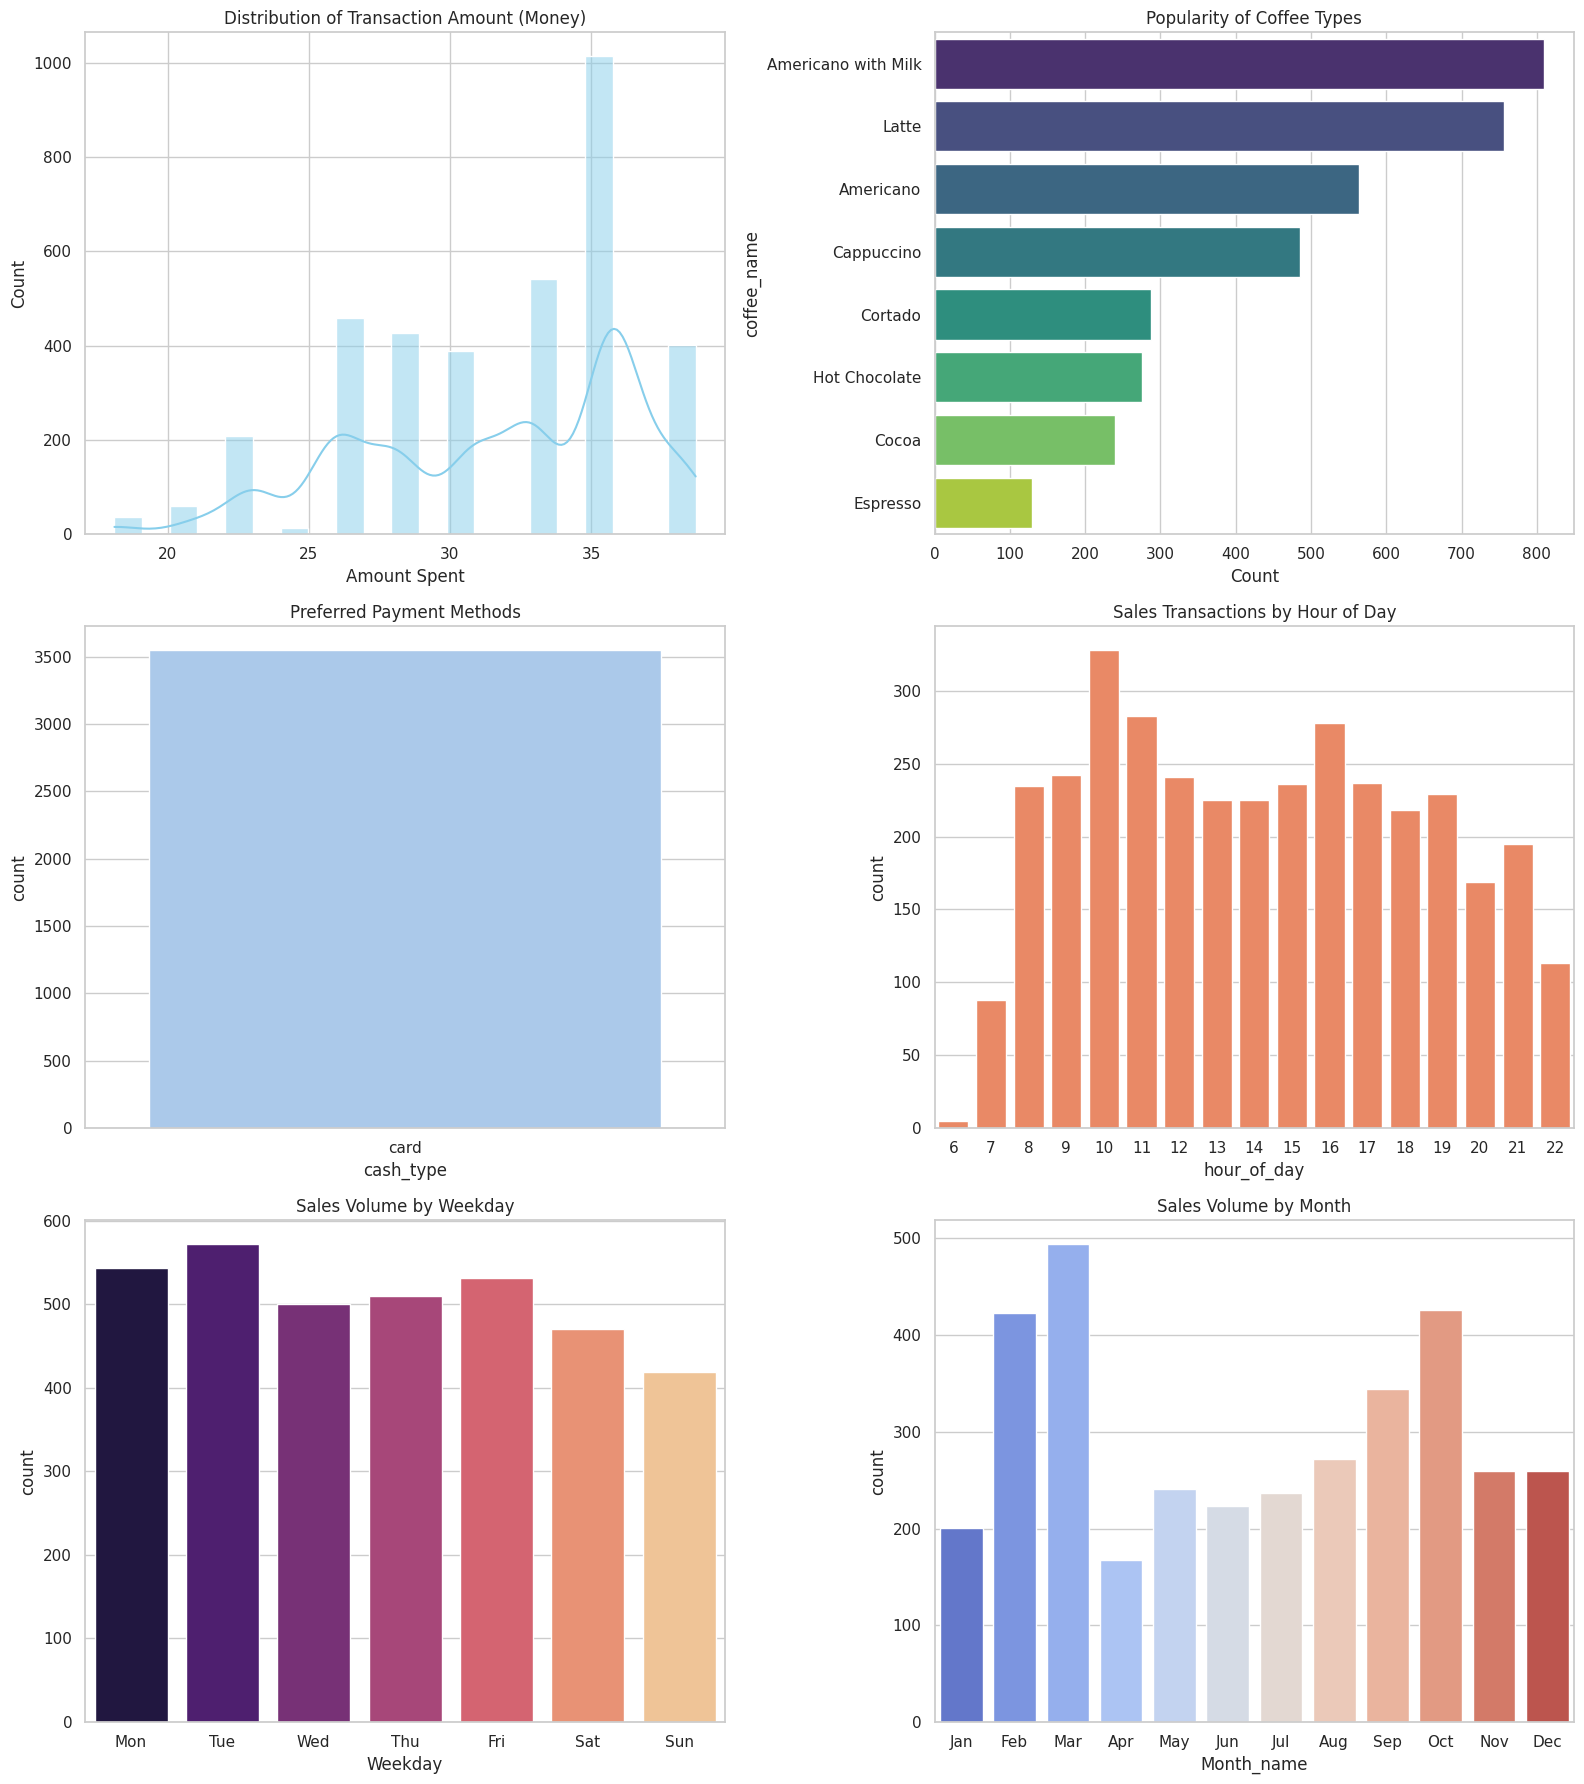

In [3]:
# 1. Statistical Summary of numeric features
print("--- Descriptive Statistics ---")
print(df.describe())

# 2. Visual Exploratory Data Analysis
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# A. Distribution of Coffee sales amount (money)
sns.histplot(data=df, x='money', kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Transaction Amount (Money)')
axes[0, 0].set_xlabel('Amount Spent')

# B. Best Selling Coffees
sns.countplot(data=df, y='coffee_name', ax=axes[0, 1], order=df['coffee_name'].value_index if hasattr(df['coffee_name'], 'value_index') else df['coffee_name'].value_counts().index, palette='viridis')
axes[0, 1].set_title('Popularity of Coffee Types')
axes[0, 1].set_xlabel('Count')

# C. Sales by Cash Type
sns.countplot(data=df, x='cash_type', ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title('Preferred Payment Methods')

# D. Sales Hourly Patterns
sns.countplot(data=df, x='hour_of_day', ax=axes[1, 1], color='coral')
axes[1, 1].set_title('Sales Transactions by Hour of Day')

# E. Sales Weekly Patterns
weekday_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
sns.countplot(data=df, x='Weekday', ax=axes[2, 0], order=[w for w in weekday_order if w in df['Weekday'].unique()], palette='magma')
axes[2, 0].set_title('Sales Volume by Weekday')

# F. Sales Monthly Patterns
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sns.countplot(data=df, x='Month_name', ax=axes[2, 1], order=[m for m in month_order if m in df['Month_name'].unique()], palette='coolwarm')
axes[2, 1].set_title('Sales Volume by Month')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42)

print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape:  {test_df.shape}")

Training set shape: (2837, 11)
Testing set shape:  (710, 11)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

# Define our features (X) and target (y)
feature_cols = ['hour_of_day', 'cash_type', 'Time_of_Day', 'Weekday', 'Month_name']
target_col = 'coffee_name'

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_test = test_df[feature_cols]
y_test = test_df[target_col]

# Preprocessing pipeline for categorical and numerical features
categorical_cols = ['cash_type', 'Time_of_Day', 'Weekday', 'Month_name']
numerical_cols = ['hour_of_day']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Create the full pipeline with a Random Forest Classifier
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Train the model
model_pipeline.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model_pipeline.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.2577

--- Classification Report ---
                     precision    recall  f1-score   support

          Americano       0.26      0.22      0.24       128
Americano with Milk       0.32      0.33      0.32       163
         Cappuccino       0.24      0.23      0.24        90
              Cocoa       0.31      0.24      0.27        45
            Cortado       0.13      0.21      0.16        48
           Espresso       0.00      0.00      0.00        20
      Hot Chocolate       0.21      0.20      0.21        60
              Latte       0.30      0.31      0.31       156

           accuracy                           0.26       710
          macro avg       0.22      0.22      0.22       710
       weighted avg       0.26      0.26      0.26       710



/tmp/ipykernel_722/3714674825.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


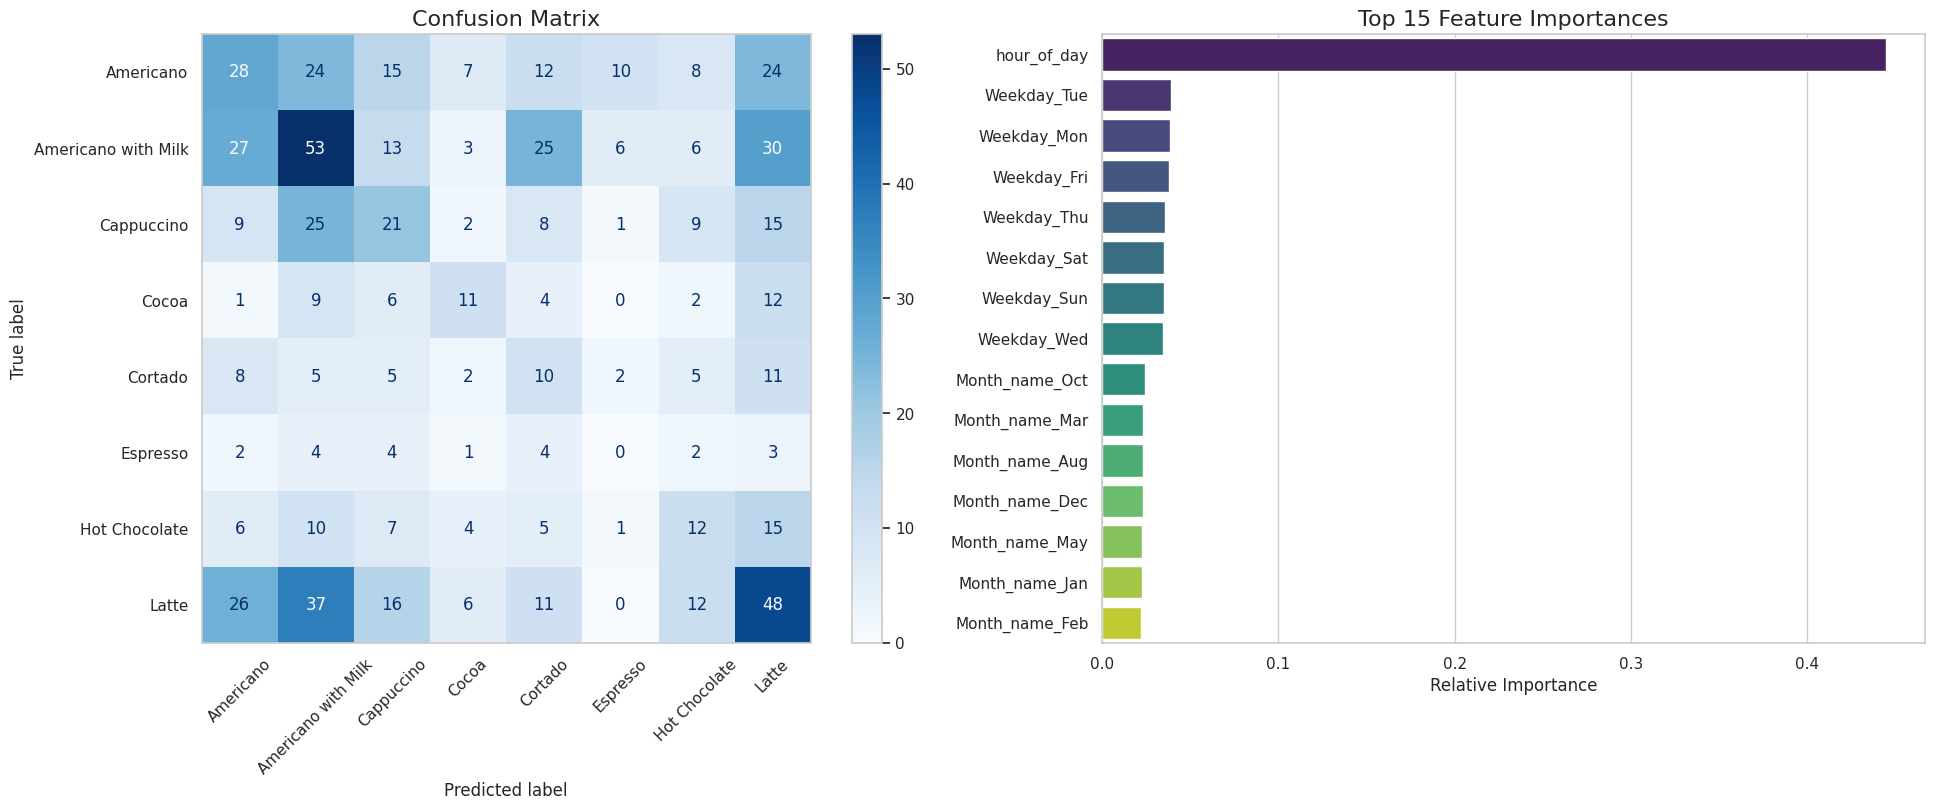

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set seaborn theme style
sns.set_theme(style="whitegrid")

# Create subplots for confusion matrix and feature importances
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model_pipeline.classes_)
disp.plot(ax=axes[0], cmap='Blues', xticks_rotation=45)
axes[0].set_title('Confusion Matrix', fontsize=16)
axes[0].grid(False) # Disable grid lines for heatmap readability

# 2. Extract and Plot Feature Importances from Pipeline
# Extract feature names from preprocessor
ohe_feature_names = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(ohe_feature_names)

importances = model_pipeline.named_steps['classifier'].feature_importances_

# Sort feature importances in descending order
indices = np.argsort(importances)[::-1]
top_n = min(15, len(all_feature_names)) # Show top 15 features

sns.barplot(
    x=[importances[i] for i in indices[:top_n]],
    y=[all_feature_names[i] for i in indices[:top_n]],
    ax=axes[1],
    palette='viridis'
)
axes[1].set_title(f'Top {top_n} Feature Importances', fontsize=16)
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

In [7]:
from sklearn.metrics import precision_recall_fscore_support
import pandas as pd

# Calculate metrics per class
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred, labels=model_pipeline.classes_)

# Calculate per-class accuracy (True Positives / Actual Support for that class)
class_accuracies = []
for i, drink in enumerate(model_pipeline.classes_):
    tp = cm[i, i]
    total_actual = support[i]
    class_acc = tp / total_actual if total_actual > 0 else 0
    class_accuracies.append(class_acc)

# Create a summary DataFrame for all unique drinks in the dataset
metrics_df = pd.DataFrame({
    'Drink Label': model_pipeline.classes_,
    'Precision': precision,
    'Recall (Sensitivity)': recall,
    'F1-Score': f1,
    'Label Accuracy': class_accuracies,
    'Sample Support': support
})

# Format the scores as percentages
formatted_df = metrics_df.style.format({
    'Precision': '{:.2%}',
    'Recall (Sensitivity)': '{:.2%}',
    'F1-Score': '{:.2%}',
    'Label Accuracy': '{:.2%}'
})

display(formatted_df)

,Drink Label,Precision,Recall (Sensitivity),F1-Score,Label Accuracy,Sample Support
0,Americano,26.17%,21.88%,23.83%,21.88%,128
1,Americano with Milk,31.74%,32.52%,32.12%,32.52%,163
2,Cappuccino,24.14%,23.33%,23.73%,23.33%,90
3,Cocoa,30.56%,24.44%,27.16%,24.44%,45
4,Cortado,12.66%,20.83%,15.75%,20.83%,48
5,Espresso,0.00%,0.00%,0.00%,0.00%,20
6,Hot Chocolate,21.43%,20.00%,20.69%,20.00%,60
7,Latte,30.38%,30.77%,30.57%,30.77%,156


In [8]:
import joblib

# Save the model pipeline to a file
model_filename = 'coffee_model_pipeline.joblib'
joblib.dump(model_pipeline, model_filename)

print(f"Model pipeline successfully saved to: {model_filename}")

Model pipeline successfully saved to: coffee_model_pipeline.joblib
